# Lecture 10 - Monte Carlo



# 10/1/26


### Midterm Notes

* Planned for 10/22
* know plan for final project by then
* look at definitions from each lesson
* know relevant formulas and mathematical relationships


## Random Numbers

### random number generators
* linear congruential random number generator.
* 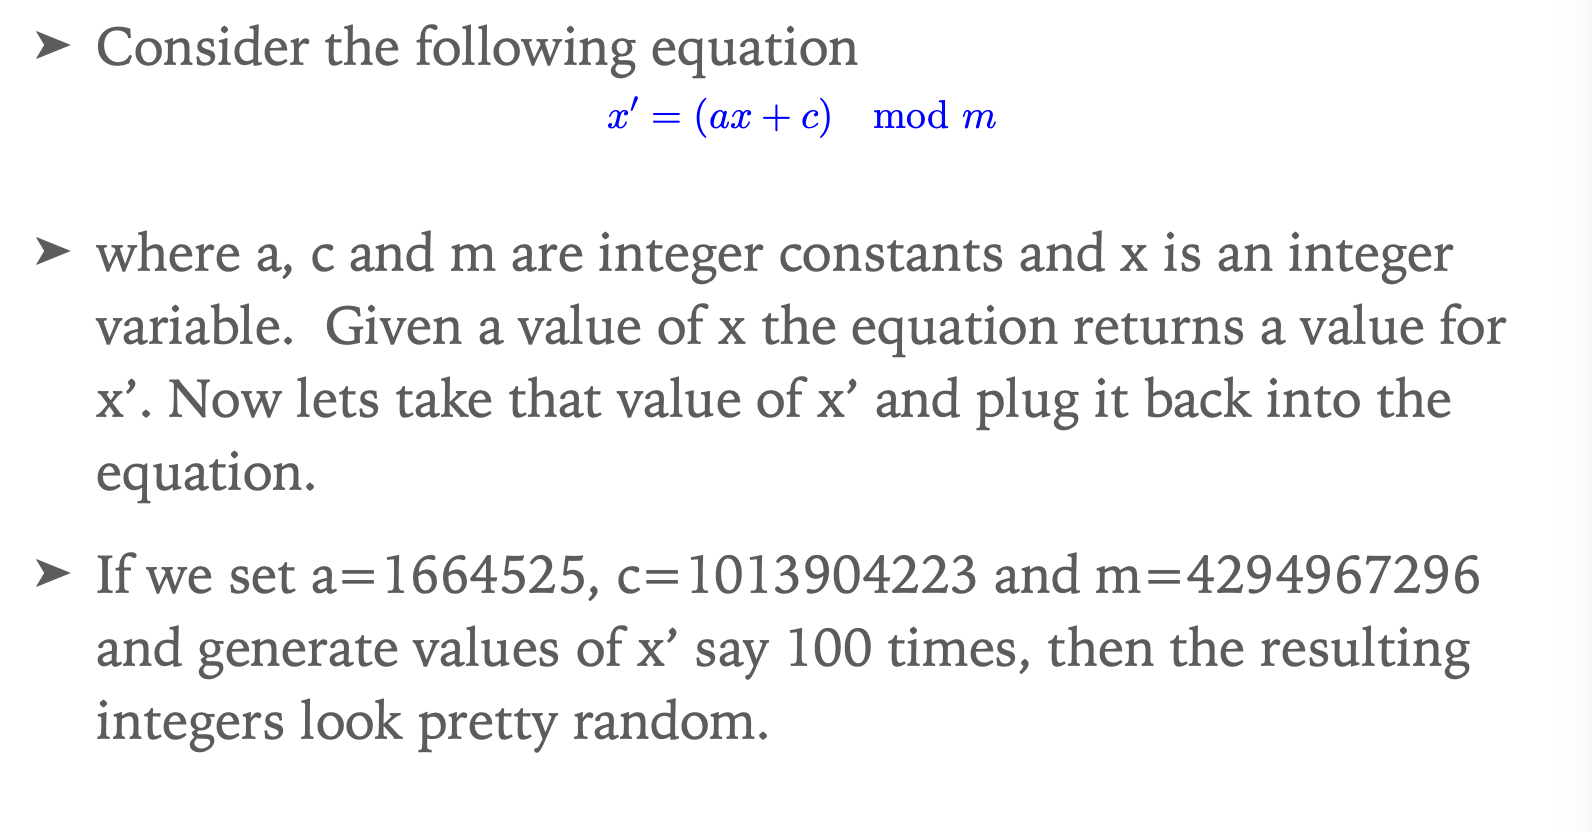
* 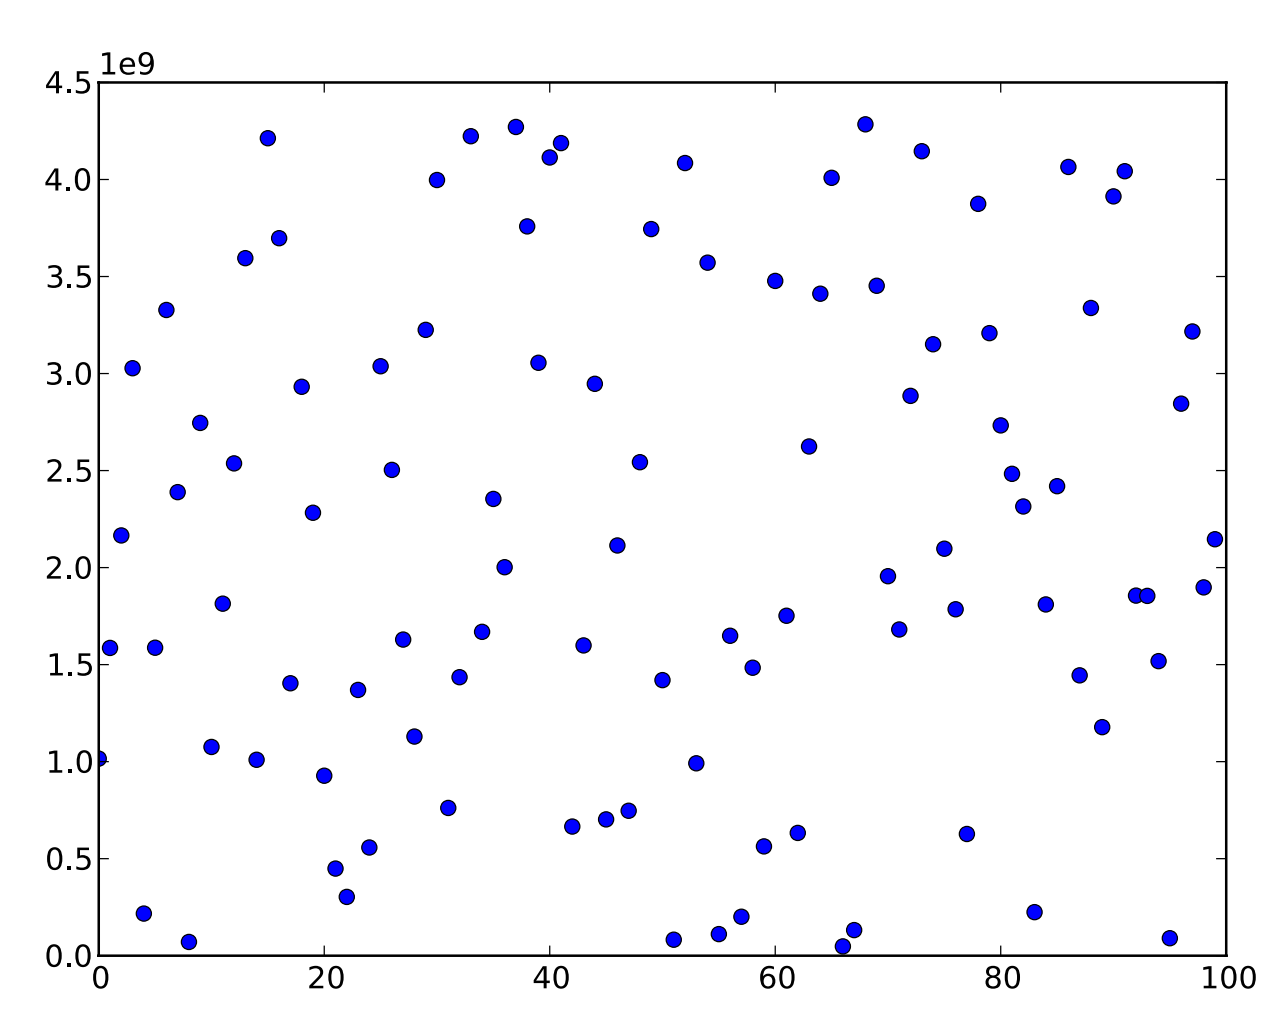
* it looks random, but if you run it again, you will get the exact same results
* This produces values in the range 0 to m-1. If we want a different
range, say 0 to 1 we can divide by m. Note this produces numbers
greater than or equal to 0, but always less than 1.


### random seed
* The original number x used to start the process is called the random seed.
* It is important because with it you can produce the same string of random numbers, even on a different computer, if you have the same values of a, c and m.
* This is very useful for debugging. If you have an error that occurs sometimes, but not always with a random number generator, you’d like to be able to produce the same sequence of numbers in order to debug it.
* But if you forget to change the seed, then your random number generator will always produce the same sequence of numbers. That is not behave very randomly.


### NUMPY RANDOM Subpackage
* In Python one can access this algorithm from the random subpackage
numpy.random. In order to start generating random numbers one wants
to create an instance of a random number generator
* the package also contains functions that return numbers from
distributions other than the uniform distribution.
* The same seed will give the same pseudorandom order of numbers.
* There are many more methods for the generator, see here
https://numpy.org/doc/stable/reference/random/generator.html#random-generator
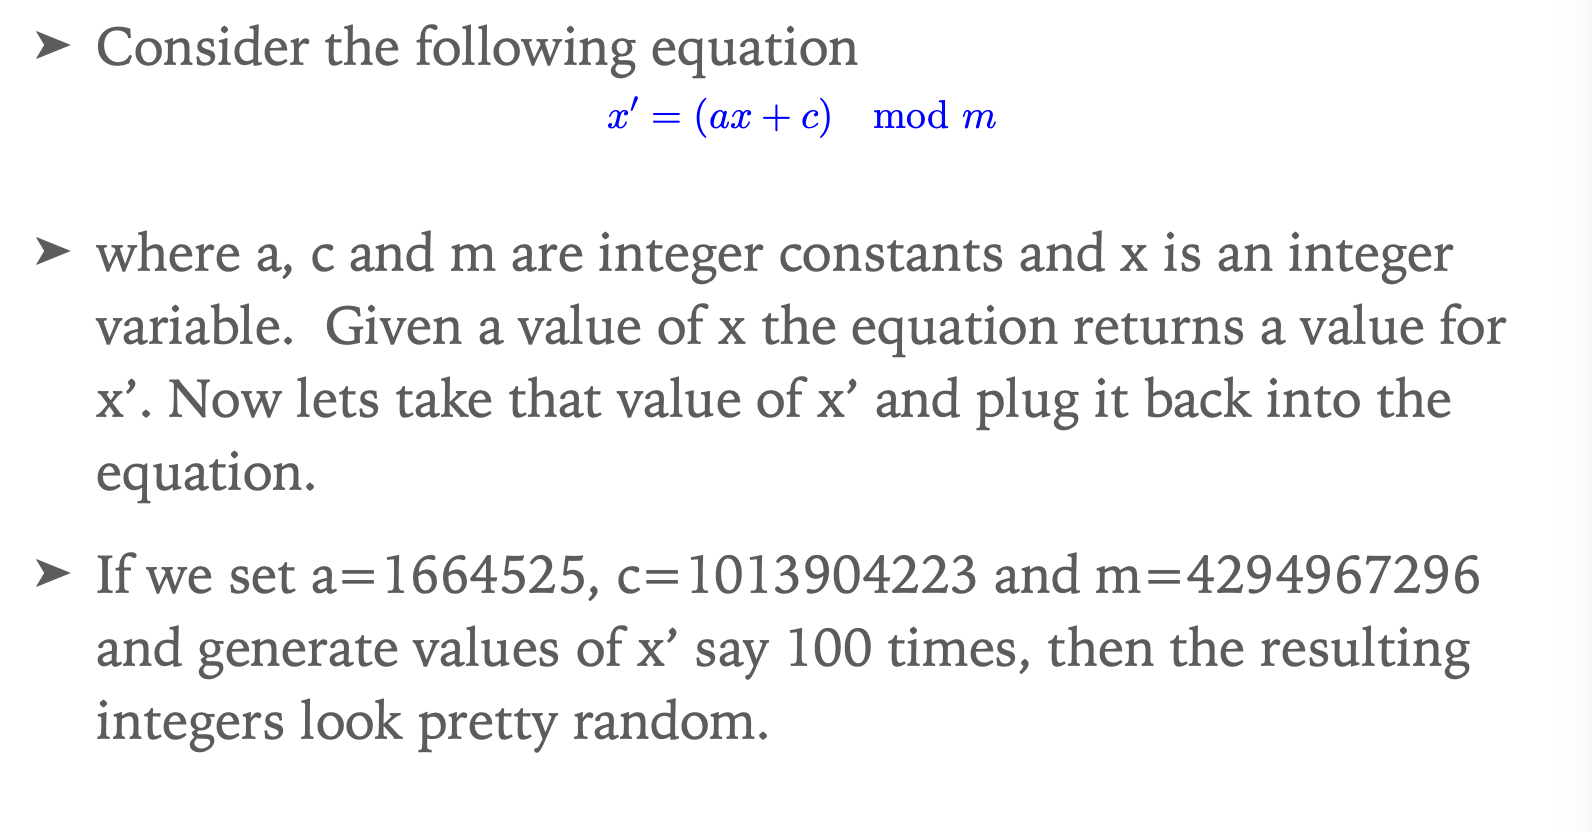

In [38]:
### NUMPY RANDOM

import numpy as np
from pyparsing import WordStart

a = [1, 2, 3, 4, 5]
rng = np.random.default_rng(seed=1234) #creates an instance of the generator
rng.random(size=2) #Returns 2 random floats f, where 0 <= f < 1
rng.integers(low=0,high=10,size=5) #Returns 5 integers between 0 and 10
rng.choice(a) #returns a random choice from the array a

np.int64(2)

## Exercise 1 - Radioactive Decay in Supernovae

The majority of light seen in a supernova explosion
comes from the radioactive decay of unstable isotopes
created in the explosion. The most important of these is
the decay of Nickel-56, 56Ni to cobalt and then iron.
Suppose we start with a sample of 1000 Nickel-56
atoms. Let us simulate the decay of these atoms over
time, mimicking the randomness of that decay using
random numbers.

On average we know that the number N of atoms in our
sample will fall off exponentially over time according to
the standard equation of radioactive decay:

N(t) = N(0)2^{-t/tau}

where τ is the half-life. Then the fraction of atoms
remaining after time t is N(t)/N(0)=2-t/τ and the
fraction that have decayed also equal to the probability
of a single atom decaying is

p(t) = 1 - 2^{-t/tau}


(2000,) (2000,) (2000,)
0.5689389268784709 0.004742813061716755


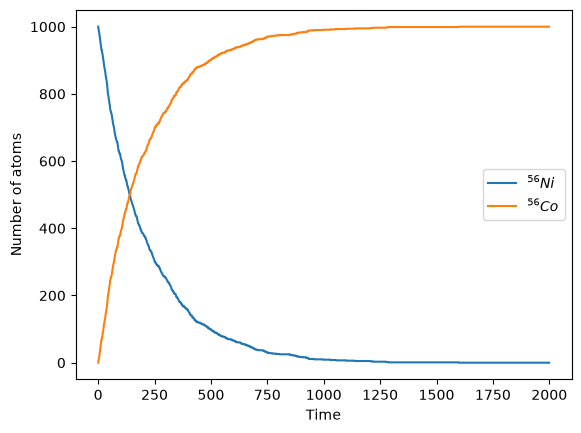

In [39]:
import numpy as np
import matplotlib.pyplot as plt


### CONSTANTS
N_Ni = 1000 # Number of nickel atoms
N_Co = 0 # Number of Cobalt atoms
tau = 6.075*24 # Half life of nickel in hours
h = 1.0 # Size of time-step in hours
p = 1 - 2**(-h/tau) # Probability of decay in one step
tmax = 2000 # Total time


### LISTS OF PLOT POINTS
tpoints = np.arange(0.0,tmax,h)
Nt = int(tmax//h)
Nipoints = np.zeros(Nt)
Copoints = np.zeros(Nt)
print(tpoints.shape,Nipoints.shape,Copoints.shape)


### INITIALIZE RANDOM NUMBER GENERATOR
rng = np.random.default_rng()
print(rng.random(),p)


### MAIN LOOP
for i in range(Nt):
    Nipoints[i] = N_Ni
    Copoints[i] = N_Co

 # NUMBER OF ATOMS IN THAT DECAY
    decay = 0
    for i in range(N_Ni):
        if rng.random() < p:
            decay += 1
    N_Ni -= decay
    N_Co += decay

### PLOTTING
plt.plot(tpoints,Nipoints,label='$^{56}Ni$')
plt.plot(tpoints,Copoints,label='$^{56}Co$')
plt.xlabel("Time")
plt.ylabel("Number of atoms")
plt.legend()
plt.show()

(5000,) (5000,) (5000,) (5000,)
0.11927108366194483 0.004742813061716755


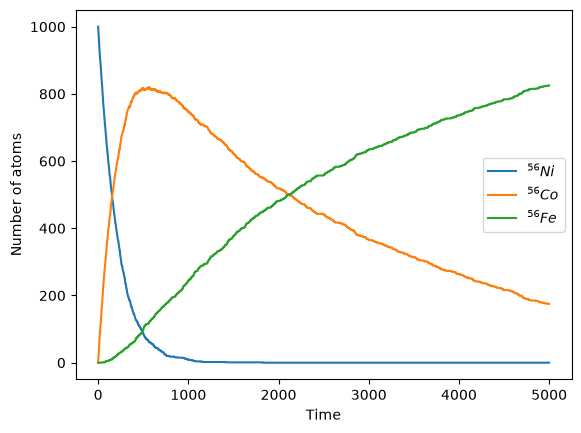

In [40]:
### CONSTANTS
N_Ni = 1000 # Number of nickel atoms
N_Co = 0 # Number of Cobalt atoms
N_Fe = 0 # Number of Iron atoms

tau1 = 6.075*24 # Half life of Nickel in hours
tau2 = 77.236*24 # Half life of Cobalt in hours

h = 1.0 # Size of time-step in hours
p1 = 1 - 2**(-h/tau1) # Probability of Nickel decay in one step
p2 = 1 - 2**(-h/tau2) # Probability of Cobalt decay in one step

tmax = 5000 # Total time


### LISTS OF PLOT POINTS
tpoints = np.arange(0.0,tmax,h)
Nt = int(tmax//h)
Nipoints = np.zeros(Nt)
Copoints = np.zeros(Nt)
Fepoints = np.zeros(Nt)
print(tpoints.shape,Nipoints.shape,Copoints.shape,Fepoints.shape)


### INITIALIZE RANDOM NUMBER GENERATOR
rng = np.random.default_rng()
print(rng.random(),p)


### MAIN LOOP
for i in range(Nt):
    Nipoints[i] = N_Ni
    Copoints[i] = N_Co
    Fepoints[i] = N_Fe

    # NUMBER OF ATOMS IN THAT DECAY --- WITHOUT FOR LOOP
    decay = (rng.random(size=N_Ni) < p1).sum()
    N_Ni -= decay
    N_Co += decay

    """
    # NUMBER OF ATOMS IN THAT DECAY --- WITH A FOR LOOP
    decay = 0
    for i in range(N_Ni):
        if rng.random() < p1:
            decay += 1
    N_Ni -= decay
    N_Co += decay
    """


    decay2 = 0
    for i in range(N_Co):
        if rng.random() < p2:
            decay2 += 1
    N_Co -= decay2
    N_Fe += decay2

### PLOTTING
plt.plot(tpoints,Nipoints,label='$^{56}Ni$')
plt.plot(tpoints,Copoints,label='$^{56}Co$')
plt.plot(tpoints,Fepoints,label='$^{56}Fe$')
plt.xlabel("Time")
plt.ylabel("Number of atoms")
plt.legend()
plt.show()

# EXERCISE 2 - MORE RADIOACTIVE DECAY

In [ ]:
### CONSTANTS
N_Bi = 10000
N_Tl = 0
N_Po = 0
N_Pb = 0

tau1 = 60.55*60*10**6 # Half life of Bi in micro-sec
tau2 = 0.299 # Half life of Po in micro-sec
tau3 = 3.053*60*10**6 # Half life of Tl in micro-sec

h = 1.0 # Size of time-step in microseconds

p1 = 1 - 2**(-h/tau1) # Probability of Bi decay in one step
p2 = 1 - 2**(-h/tau2) # Probability of Po decay in one step
p3 = 1 - 2**(-h/tau3) # Probability of Tl decay in one step

tmax = 1000*60.55*60*10**6 # Total time (enough for 1000 Bi decays)


### LISTS OF PLOT POINTS
tpoints = np.arange(0.0,tmax,h)
Nt = int(tmax//h)
Bipoints = np.zeros(Nt)
Tlpoints = np.zeros(Nt)
Popoints = np.zeros(Nt)
Pbpoints = np.zeros(Nt)
print(tpoints.shape,Bipoints.shape,Tlpoints.shape,Popoints.shape,Pbpoints.shape)


### INITIALIZE RANDOM NUMBER GENERATOR
rng = np.random.default_rng()
print(rng.random(),p)


### MAIN LOOP
for i in range(Nt):
    Bipoints[i] = N_Bi
    Tlpoints[i] = N_Tl
    Popoints[i] = N_Po
    Pbpoints[i] = N_Pb

    # NUMBER OF ATOMS IN THAT DECAY --- WITHOUT FOR LOOP
    decay = (rng.random(size=N_Bi) < p1).sum()
    N_Bi -= decay
    N_Tl += decay

    decay2 = (rng.random(size=N_Bi) < p2).sum()
    N_Bi -= decay
    N_Po += decay

#####################    UNFINISHED!!!!!!!   ##########################################
    """
    # NUMBER OF ATOMS IN THAT DECAY --- WITH A FOR LOOP
    decay = 0
    for i in range(N_Ni):
        if rng.random() < p1:
            decay += 1
    N_Ni -= decay
    N_Co += decay
    """


    decay2 = 0
    for i in range(N_Co):
        if rng.random() < p2:
            decay2 += 1
    N_Co -= decay2
    N_Fe += decay2

### PLOTTING
plt.plot(tpoints,Nipoints,label='$^{56}Ni$')
plt.plot(tpoints,Copoints,label='$^{56}Co$')
plt.plot(tpoints,Fepoints,label='$^{56}Fe$')
plt.xlabel("Time")
plt.ylabel("Number of atoms")
plt.legend()
plt.show()

# EXERCISE 3 --

* Redo the calculation from Example 1, but
this time using the faster method just
described. Using the transformation
method, generate 1000 random numbers
from the nonuniform distribution to
represent the times of decay of 1000
atoms of 56Ni (which has half-life 6.075
days). Then make a plot showing the
number of atoms that have not decayed as
a function of time, i.e., a plot as a function
of t showing the number of atoms whose
chosen decay times are greater than t.
* Hint: You may find it useful to know that
the package numpy contains a function
sort that will rearrange the elements of an
array in increasing order. That is, “b =
sort(a)” returns a new array b containing
the same numbers as a, but rearranged in
order from smallest to largest.

Text(0.5, 0, 'Time Step of Decay (?)')

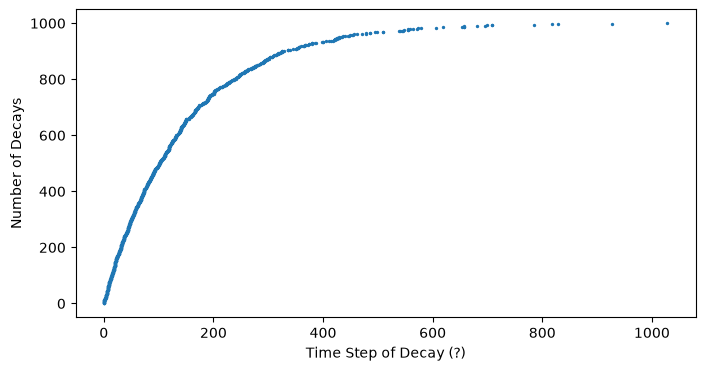

In [22]:
import numpy as np
from matplotlib import pyplot as plt
rng = np.random.default_rng(seed=1234) #creates an instance of the generator


z = rng.random(size=1000)

def transformation_x(tau, z):
    mu = 1/tau
    x = -1/mu * np.log(1-z)
    # p = mu * (np.e)**(-mu * x)
    return x

x = transformation_x(6.075*24, z)
# print(x)

x_new = np.sort(x)
# print(x_new)

y = np.arange(0, 1000, 1)

plt.figure(figsize=(8,4))
plt.scatter(x_new, y, s=2)
plt.ylabel("Number of Decays")
plt.xlabel("Time Step of Decay (?)")


# MONTE CARLO Example

In [25]:
import numpy as np

def f(x):
    return (np.sin(1/(x*(2-x))))**2

rng = np.random.default_rng()
N = 10000
count = 0

for i in range(N):
    x = 2*rng.random()
    y = rng.random()
    if y<f(x):
        count += 1

I = 2*count/N

print("I = ",I)

I =  1.467


# Exercise 10.5


* Write a program to evaluate
the integral below using the
‘hit-or-miss’ method with
10,000 points. Also evaluate
the error.
* Now estimate the integral
again using the mean value
method. Again estimate your
error.

In [35]:
# imports
from scipy.integrate import quad

# define function
def function(x):
    return (np.sin(1 / (x*(2-x))))**2



#### HIT OR MISS METHOD
area = 2
N = 10000
count = 0
for i in range(N):
    x = 2*rng.random()
    y = rng.random()
    if y<function(x):
        count += 1
I = area * count / N
print("Integral via Hit or Miss = ", I)




#### MEAN VALUE METHOD
area = 2
N = 10000
count = 0
for i in range(N):
    x = 2*rng.random()
    y = rng.random()
    if y<function(x):
        count += 1
I = area * count / N
print(I)

"""









x_ax = 2 * rng.random(size=10000)  # random numbers from 0 to 2, instead of 0 to 1

for i in x_ax:
    integral.append(quad(function, 0, 2))

plt.plot(x_ax, integral)"""




1.46


'\n\n\n\n\n\n\n\n\n\nx_ax = 2 * rng.random(size=10000)  # random numbers from 0 to 2, instead of 0 to 1\n\nfor i in x_ax:\n    integral.append(quad(function, 0, 2))\n\nplt.plot(x_ax, integral)'

## 10/8/26
# Integration in Many Dimensions

* **Monte
Carlo integration is used to evaluate high dimensional
integrals.**
* For our previous integration methods:
* performing those techniques over more dimensions required us to sample values of the integrand over a grid. If we had four dimensions and we used 100 points in each dimension that would be $100^4$ or 100 million points.
* This is doable, but rather slow and higher dimensions quickly
become undoable. Monte Carlo integration can give
reasonably good answers with far fewer points

\

* Generalizing the mean value method is straightforward. Now
we have:
* $I ~= \frac{V}{N} \sum_{i=1}^{N}f(r_i)$
* where ri is now a vector that is chosen randomly from the
volume to be integrated over

\

## Importance Sampling
* While Monte Carlo integration is a good approach for
pathological functions, there are still some functions where it
doesn’t preform well. Particularly, cases where the integrand
contains a divergence. For example
* $I = \int_{0}^{1} \frac{x^{-1/2}}{e^x + 1}dx $
* which arises in the theory of Fermi gasses. While this
integrand diverges at x=0, the integral is finite. But if you try
to evaluate it with the mean value method you can run into
problems because if your sample has an x close to zero it can
contribute a very large amount.

\

* **We can get around this problem by drawing our x point non
uniformly from the integration interval. This technique is
called importance sampling. For any general function g(x) we
can define a weighted average over the interval from a to b.**

# EXERCISE 10.7 - VOLUME OF A HYPERSPHERE (10D)

In [8]:
import numpy as np

V = 4   # volume of the space you are probing (2x2 square)
N = 10000   # number of probes



xrng = np.random.default_rng(seed=1234)
yrng = np.random.default_rng(seed=42)


x = xrng.random(size=N)
y = yrng.random(size=N)

f_of_xy = (np.zeros(N))

# print(f_of_xy)

"""
for i in range(len(x)):
    if x[i]**2 + y[i]**2 <= 1:
        f_of_xy[i] = 1
    else: f_of_xy[i] = 0

print(f_of_xy)


def I(x,y):
    return (V/N) * """

[0. 1. 0. ... 1. 1. 1.]


'\ndef I(x,y):\n    return (V/N) * '

In [ ]:




44

# DID NOT SAVE WORK
# Above work is wrong
# get answers from someone


# Statistical Mechanics


* So let’s try Monte Carlo, instead of evaluating all states, we will
randomly sample N states and as N gets larger we will get closer
to the correct value
* 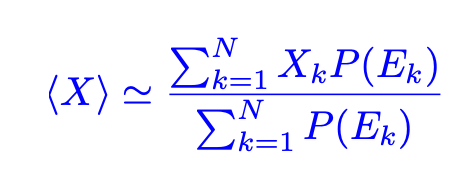
* Unfortunately in most situations this will not work. The
Boltzmann probability is exponential, so the vast majority of
states of exponentially small probability. Thus mosts of our
randomly chosen energies contribute almost nothing to this sum.
* But we have just discussed a method to overcome this problem,
important sampling. If we weight which energies we choose
randomly then we can get the important ones in our sum.


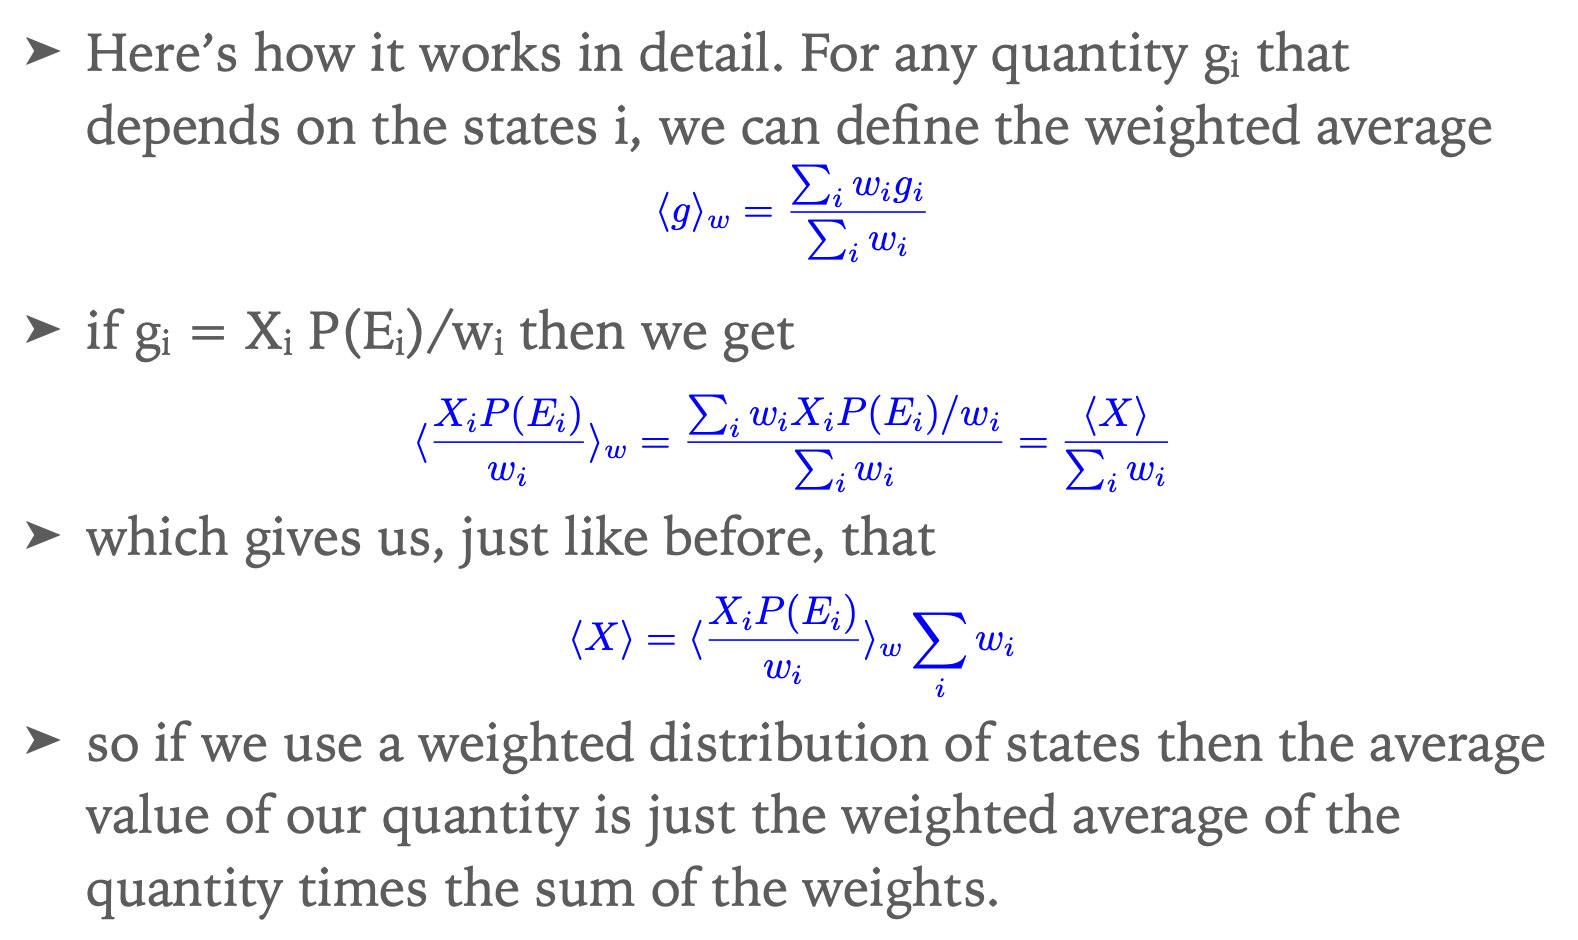

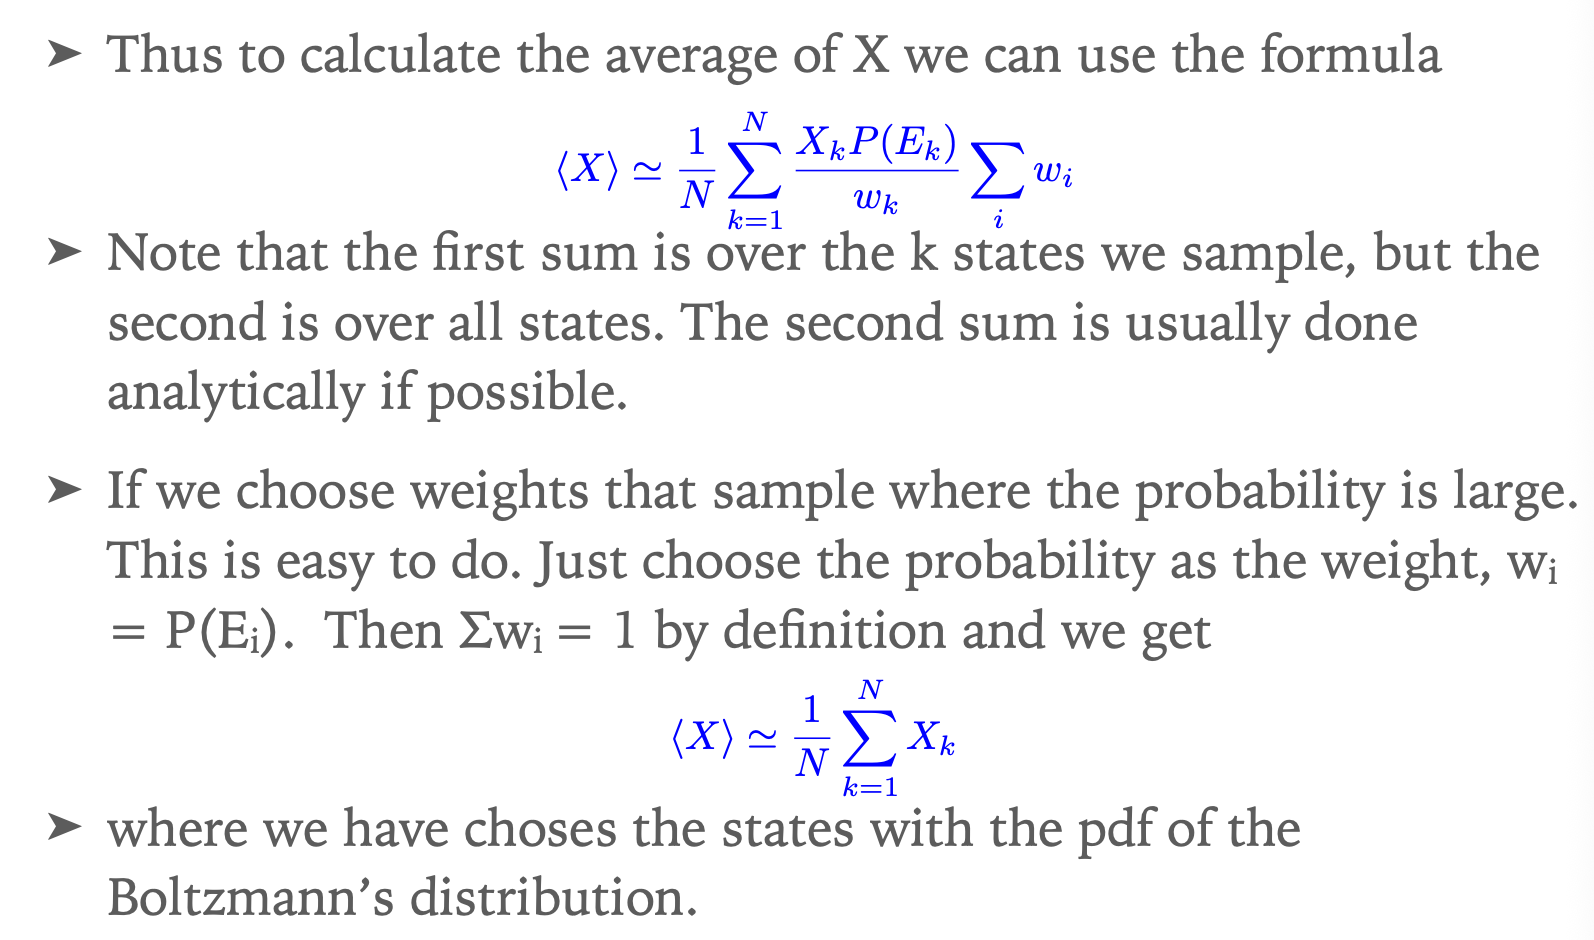



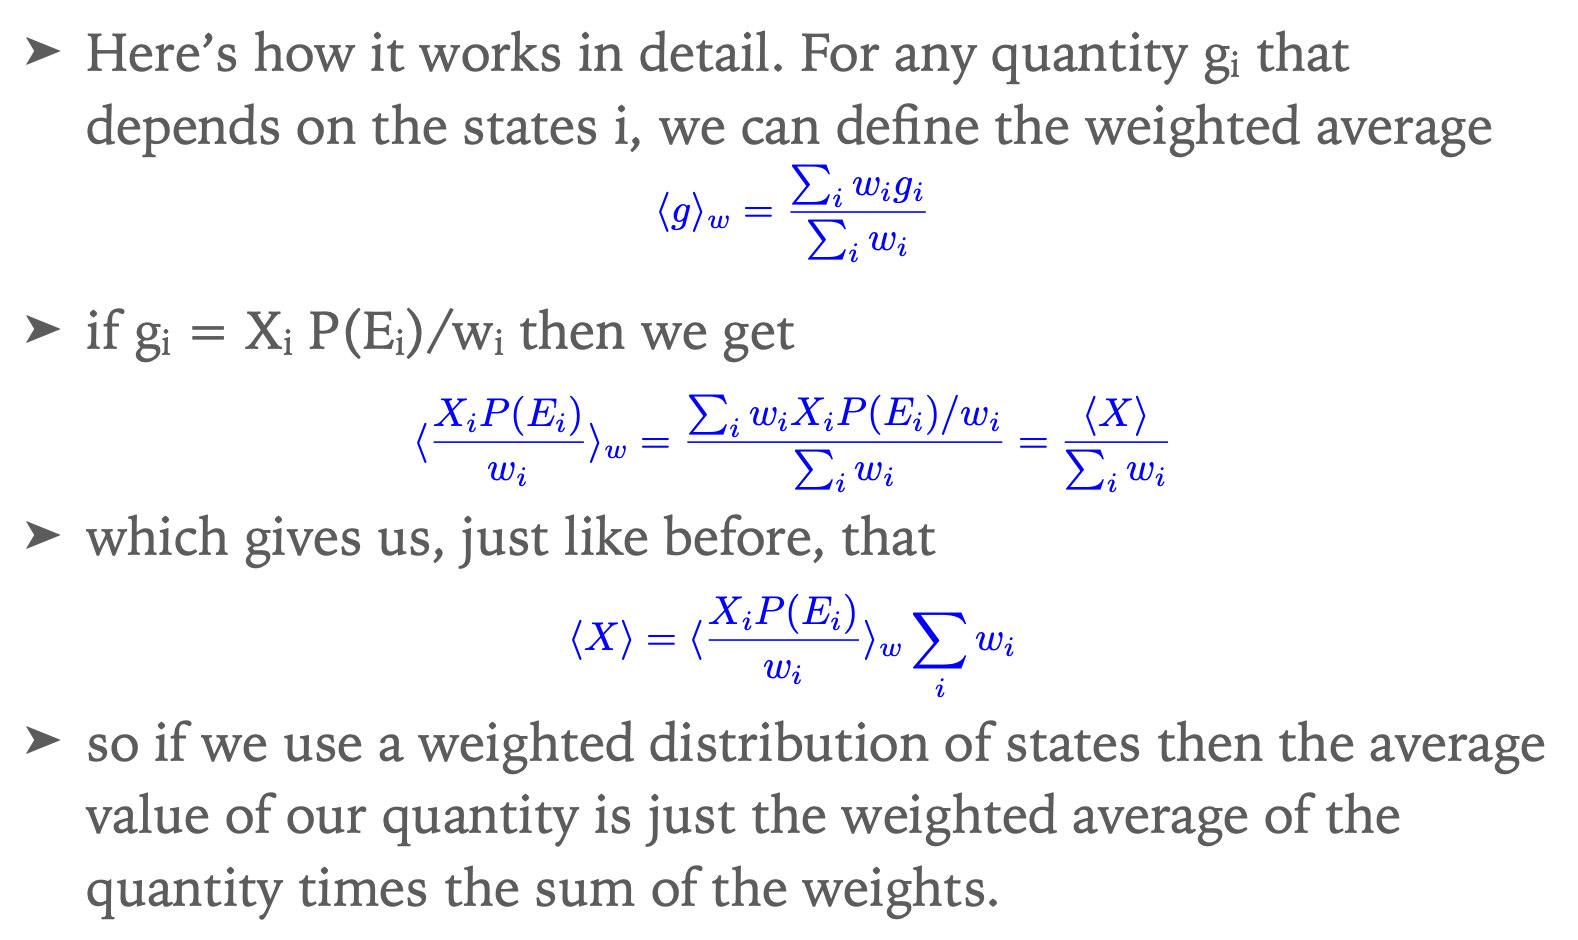

### IMPORTANCE SAMPLING AND STATISTICAL MECHANICS
* An alternative (and more physical) way of thinking about this
approach is to think about the Monte Carlo as the behavior of an
actual system.
* If we had some physical system it would start off in some initial
state. Then it would move to another state with a probability given
by Boltzmann. It would then keep changing states, each time with a
probability related to its Boltzmann distribution.
*  If we measured a quantity for the system we would get an average of
the values that quantity has over the states the system has been in
while we performed our measurement.
* Thinking of it this way importance sampling is just physically
modeling what the system might do in an actual physics experiment.

# MARKOV CHAIN
* It looks like we have a general method for statistical
mechanics, there is still one problem, we have to calculate
P(Ei).
* The exponential part is easy, but remember the probability
was also normalized by the sum of states Z, called the
partition function. Unfortunately, it is usually not easy to
calculate Z.
* Luckily there is a solution to this problem, **we can make our
calculation without knowing Z by a technique called a Markov
chain.**




* Our goal is to have a set of states for the sum to get an
average. We will do this by generating a sequence of states,
that is the chain part of the Markov chain.
Let’s start with some state i. Now the next state, instead of
choosing it randomly from the full ensemble, let’s just make a
small change to the system to get a new state j.
* The probability of going from state i to j is given by a transition
probability Tij. If we can choose our transition probability the
right way then we can issue then we can insure that the
chance of ending up at any one state on the chain is the
Boltzmann probability.
* ![image.png](attachment:fbb6cdf9-62b1-4957-a72c-98a97a1156f2.png)




# METROPOLIS ALGORITHM




WORDS
* WORDS
* WORDS
* WORDS
*

In [6]:
# EXAMPLE 10.3 - MONTE CARLO SIMULATION OF AN IDEAL GAS
import numpy as np

T = 10.0
pi = np.pi
N = 1000
steps = 250000
# Create a 2D array to store the quantum numbers
n = np.ones([N,3],int)
# Main loop
eplot = []
E = 3*N*pi*pi/2
for k in range(steps):
    # Choose the particle and the move
    i = randrange(N)
    j = randrange(3)
    if random()<0.5:
        dn = 1
        dE = (2*n[i,j]+1)*pi*pi/2
    else:
        dn = -1
        dE = (-2*n[i,j]+1)*pi*pi/2
 # Decide whether to accept the move
    if n[i,j]>1 or dn==1:
        if random()<exp(-dE/T):
            n[i,j] += dn
            E += dE
    eplot.append(E)

# Make the graph
plot(eplot); ylabel("Energy"); show()


NameError: name 'randrange' is not defined